# Atividade computacional: Segmentação, Operações Morfológicas e Extração de Características
**Unidade:** 3 | **Capítulo:** 1 | **Tarefa:** 4

## 1. Introdução

Filtrar uma imagem melhora sua qualidade, mas não diz nada sobre o que ela contém. Para contar, medir ou classificar objetos, um algoritmo precisa primeiro decidir **quais pixels pertencem a cada objeto** — e essa decisão é tomada sobre números de intensidade, não sobre formas reconhecíveis. Uma pessoa vê 24 moedas imediatamente; para o computador, a imagem é uma matriz de 116 mil valores entre 0 e 255.

O caminho clássico para essa tarefa é um *pipeline* em etapas encadeadas: a **segmentação** separa objetos do fundo, as **operações morfológicas** corrigem os defeitos da máscara resultante, a **análise de componentes conectados** transforma a máscara em objetos individuais e, por fim, cada objeto é descrito por **características** numéricas de forma, intensidade e textura. Como cada etapa recebe a saída da anterior, um erro no início se propaga: uma moeda partida na segmentação vira dois objetos na contagem e duas linhas erradas na tabela de características.

Neste notebook, o pipeline é aplicado à imagem `coins` da biblioteca `skimage.data`. São comparados três métodos de segmentação (limiarização global de Otsu, limiarização adaptativa e watershed sobre o gradiente de Sobel), quatro operações morfológicas (erosão, dilatação, abertura e fechamento) e nove características por objeto, com cada etapa analisada visualmente e por medições.

### Preparação do ambiente

Bibliotecas utilizadas: **scikit-image** (imagem de exemplo, segmentação, rotulagem e descritores GLCM), **SciPy** (operações morfológicas binárias e preenchimento de furos), **NumPy** (operações matriciais), **pandas** (tabelas) e **Matplotlib** (visualização).

As operações morfológicas binárias são feitas com `scipy.ndimage`, e não com `skimage.morphology.binary_*`, porque essas funções foram marcadas como obsoletas na versão 0.26 do scikit-image.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, filters, morphology, measure, segmentation, color
from skimage.feature import graycomatrix, graycoprops

RAIO_ELEMENTO = 3          # raio do disco usado nas operações morfológicas (ver 4.1)
LIMIAR_FUNDO = 30          # marcador de fundo do watershed: pixels abaixo deste valor
LIMIAR_MOEDA = 150         # marcador de moeda do watershed: pixels acima deste valor

plt.rcParams['image.interpolation'] = 'nearest'   # impede o matplotlib de suavizar a exibição

## 2. Aquisição da imagem

Foi escolhida a imagem `coins` da biblioteca `skimage.data`: uma fotografia de moedas gregas antigas sobre fundo escuro, com **múltiplos objetos separados** — o caso sugerido pela atividade. Por ser uma imagem padrão da biblioteca, o resultado é reprodutível em qualquer ambiente, sem depender de arquivos externos.

Informações extraídas da imagem:

| Informação | Por que importa |
|---|---|
| Resolução | Define a escala de tudo o que vem depois: raio do elemento estruturante, áreas e perímetros |
| Tipo / faixa | 8 bits → valores de 0 a 255, faixa em que os limiares serão escolhidos |
| Média e desvio padrão | Linha de base do brilho e do contraste da cena |
| Percentis 1% e 99% | Indicam se a imagem usa toda a faixa e se há saturação |

### 2.1 Carregamento e ficha técnica

A imagem já vem em escala de cinza, em um único canal; não há conversão de cor.

In [ ]:
img = data.coins()

ficha = pd.DataFrame({
    'Valor': {
        'Origem': 'skimage.data.coins()',
        'Resolução': f'{img.shape[1]}×{img.shape[0]} ({img.size:,} pixels)'.replace(',', '.'),
        'Tipo': f'{img.dtype}, {img.dtype.itemsize * 8} bits',
        'Faixa observada': f'{img.min()} – {img.max()}',
        'Média': round(float(img.mean()), 2),
        'Desvio padrão': round(float(img.std()), 2),
        'Percentil 1%': np.percentile(img, 1),
        'Percentil 99%': np.percentile(img, 99),
        'Pixels em 0 ou 255 (%)': round(100 * np.mean((img == 0) | (img == 255)), 3),
    }
})
ficha

,Valor
Origem,skimage.data.coins()
Resolução,384×303 (116.352 pixels)
Tipo,"uint8, 8 bits"
Faixa observada,1 – 252
Média,96.86
Desvio padrão,52.88
Percentil 1%,23.0
Percentil 99%,216.0
Pixels em 0 ou 255 (%),0.0


### 2.2 Visualização da imagem

Imagem original e histograma dos níveis de cinza.

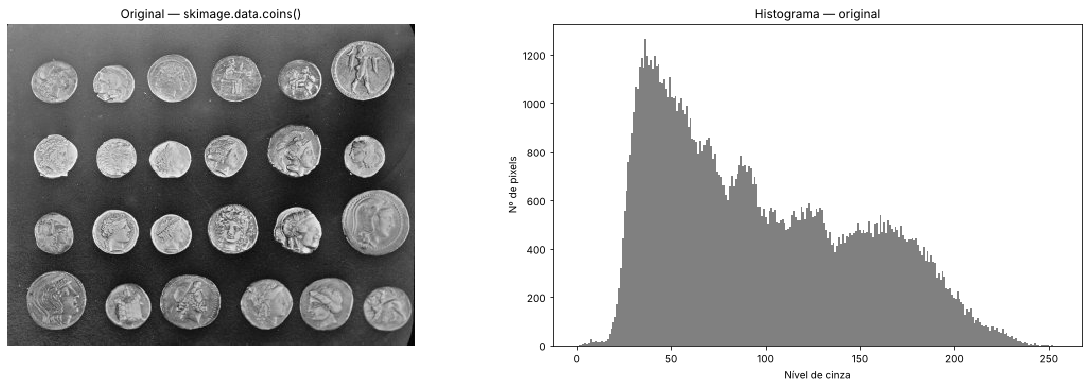

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original — skimage.data.coins()')
axes[0].axis('off')

axes[1].hist(img.ravel(), bins=256, range=(0, 255), color='gray')
axes[1].set_title('Histograma — original')
axes[1].set_xlabel('Nível de cinza')
axes[1].set_ylabel('Nº de pixels')
plt.tight_layout()
plt.show()

### 2.3 Medições de apoio

Algumas afirmações da interpretação dependem de números que a figura não mostra diretamente. Esta célula estima o **brilho do fundo** em cada parte da imagem.

Para isso, é usada uma **abertura em tons de cinza** com um disco de raio 35 px, maior que a maior moeda (raio ≈ 32 px). A abertura remove toda estrutura clara menor que o disco — ou seja, apaga as moedas — e o que sobra é uma estimativa do fundo. As médias são calculadas por faixas horizontais (de cima para baixo) e verticais (da esquerda para a direita).

In [ ]:
fundo_estimado = morphology.opening(img, morphology.disk(35))

faixas_lin = [round(float(fundo_estimado[y:y + 76].mean()), 1) for y in range(0, img.shape[0], 76)]
faixas_col = [round(float(fundo_estimado[:, x:x + 96].mean()), 1) for x in range(0, img.shape[1], 96)]

pd.DataFrame({
    'Valor': {
        'Fundo estimado: mínimo → máximo': f'{fundo_estimado.min()} → {fundo_estimado.max()}',
        'Brilho do fundo por faixa (topo → base)': faixas_lin,
        'Brilho do fundo por faixa (esq → dir)': faixas_col,
        'Pixels acima de 150 (%)': round(100 * np.mean(img > 150), 1),
        'Pixels abaixo de 30 (%)': round(100 * np.mean(img < 30), 1),
    }
})

,Valor
Fundo estimado: mínimo → máximo,1 → 107
Brilho do fundo por faixa (topo → base),"[75.3, 44.3, 27.4, 25.3]"
Brilho do fundo por faixa (esq → dir),"[59.5, 43.9, 35.8, 33.4]"
Pixels acima de 150 (%),20.4
Pixels abaixo de 30 (%),4.6


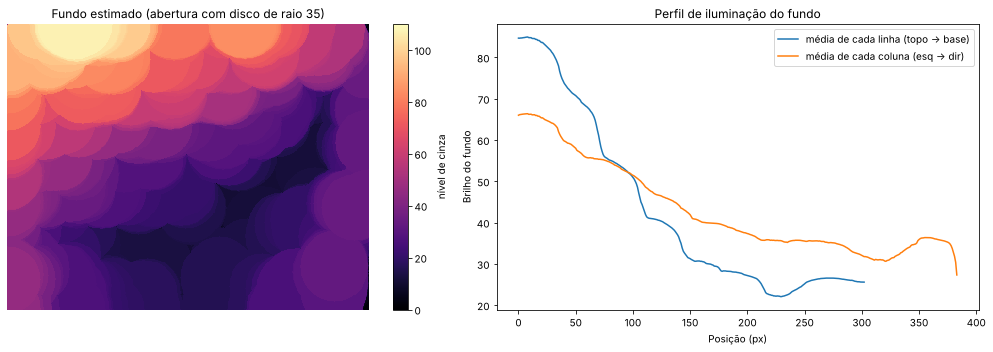

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mapa = axes[0].imshow(fundo_estimado, cmap='magma', vmin=0, vmax=110)
plt.colorbar(mapa, ax=axes[0], fraction=0.035, label='nível de cinza')
axes[0].set_title('Fundo estimado (abertura com disco de raio 35)')
axes[0].axis('off')

axes[1].plot(fundo_estimado.mean(axis=1), label='média de cada linha (topo → base)')
axes[1].plot(fundo_estimado.mean(axis=0), label='média de cada coluna (esq → dir)')
axes[1].set_xlabel('Posição (px)')
axes[1].set_ylabel('Brilho do fundo')
axes[1].set_title('Perfil de iluminação do fundo')
axes[1].legend()
plt.tight_layout()
plt.show()

### 2.4 Interpretação

* **Observação visual:** 24 moedas em quatro fileiras, todas separadas entre si, sobre um fundo escuro e liso. Os tamanhos variam bastante: as moedas da segunda fileira são pequenas, enquanto a última da terceira fileira e as da base são grandes. Cada moeda tem relevo interno (efígies, figuras, inscrições), com regiões escuras dentro do próprio objeto.

* **Histograma e estatísticas:** perfil bimodal, mas com os dois grupos mal separados. O pico do fundo fica nos tons escuros, e as moedas formam uma distribuição larga nos tons claros, com uma faixa intermediária extensa entre os dois. A imagem usa quase toda a faixa (percentis 1% e 99% em 23 e 216) e não tem pixels saturados.

* **Iluminação não uniforme:** o fundo não tem um brilho único. O fundo estimado vai de 75,3 na faixa superior a 25,3 na base, e de 59,5 à esquerda a 33,4 à direita: a luz vem do **canto superior esquerdo**, e o fundo dessa região chega a ~107, um valor próximo do brilho das partes escuras das moedas. Isso significa que **o mesmo nível de cinza pode ser fundo em uma parte da imagem e moeda em outra**.

* **Consequências previstas (a confirmar nas próximas seções):**
   1. **Falha da limiarização global:** um limiar único deve classificar parte do fundo claro do topo como moeda e, ao mesmo tempo, abrir buracos nas moedas mais escuras da base.
   2. **Furos internos:** o relevo escuro dentro das moedas deve gerar furos na máscara, exigindo um preenchimento antes de medir área e perímetro.
   3. **Intensidade contaminada:** a intensidade média de cada moeda deve refletir em parte a **posição** dela na imagem (iluminação), e não apenas o metal ou o desgaste da moeda.

## 3. Segmentação

### 3.1 Conceito

Segmentar é atribuir a cada pixel um rótulo — aqui, **moeda** ou **fundo**. Foram testadas três estratégias, de complexidade crescente:

**Limiarização global (Otsu).** Usa um único limiar $T$ para a imagem inteira:

$$g(x,y) = \begin{cases} 1 & \text{se } f(x,y) > T \\ 0 & \text{caso contrário} \end{cases}$$

O método de Otsu escolhe $T$ automaticamente, testando todos os valores possíveis e ficando com o que **maximiza a variância entre as duas classes** (equivalentemente, minimiza a variância dentro de cada uma). Funciona bem quando o histograma tem dois picos bem separados.

**Limiarização adaptativa (local).** O limiar passa a depender da posição: $T(x,y)$ é a média ponderada (gaussiana) da vizinhança de cada pixel, menos uma constante. Em teoria, compensa a iluminação desigual, porque cada região é comparada apenas com o próprio entorno.

**Detecção de bordas + watershed.** Em vez de perguntar "este pixel é claro?", o método pergunta "onde estão as bordas?":

1. o **gradiente de Sobel** gera um *mapa de elevação*, alto nas bordas das moedas e baixo nas regiões homogêneas;
2. são definidos **marcadores** apenas onde não há dúvida: fundo (< 30) e moeda (> 150);
3. o **watershed** "inunda" o mapa a partir dos marcadores, e cada pixel ambíguo recebe o rótulo do marcador que o alcança primeiro. As frentes de inundação se encontram nas cristas do gradiente — ou seja, exatamente nas bordas.

**Implementação.** Otsu e a limiarização adaptativa usam `skimage.filters.threshold_otsu` e `threshold_local`. Para a adaptativa, foi usado um bloco de 101×101 px (pouco maior que o diâmetro das moedas maiores, para que cada janela contenha moeda e fundo) e um *offset* de −10. O watershed usa `skimage.segmentation.watershed`. Os limiares dos marcadores (30 e 150) foram escolhidos a partir do histograma: abaixo de 30 há apenas fundo, e acima de 150, apenas moeda, inclusive nas regiões mais iluminadas do fundo (máximo ≈ 107). A sensibilidade a essa escolha é medida em 3.4.

### 3.2 Implementação

Para cada método, são registrados o número de regiões conectadas (o ideal seria 24), o número de **regiões pequenas** (< 50 px, que só podem ser ruído ou fragmentos) e a **maior região** (uma região muito maior que a maior moeda, de ~3.100 px, indica moedas fundidas entre si ou com o fundo).

In [ ]:
def resumo_mascara(mascara):
    # Conta as regiões conectadas de uma máscara binária e mede seu tamanho.
    rotulos = measure.label(mascara, connectivity=2)
    areas = np.bincount(rotulos.ravel())[1:]          # descarta o rótulo 0 (fundo)
    return {
        'Regiões': len(areas),
        'Regiões < 50 px': int(np.sum(areas < 50)),
        'Maior região (px)': int(areas.max()),
        'Pixels de objeto (%)': round(100 * mascara.mean(), 1),
    }

# --- 1) Limiarização global (Otsu) ---
limiar_otsu = filters.threshold_otsu(img)
seg_otsu = img > limiar_otsu

# --- 2) Limiarização adaptativa ---
limiar_local = filters.threshold_local(img, block_size=101, offset=-10)
seg_local = img > limiar_local

# --- 3) Sobel + watershed ---
elevacao = filters.sobel(img)
marcadores = np.zeros_like(img)
marcadores[img < LIMIAR_FUNDO] = 1                   # fundo certo
marcadores[img > LIMIAR_MOEDA] = 2                   # moeda certa
seg_ws = segmentation.watershed(elevacao, marcadores) == 2

segmentacoes = {
    f'Otsu global (T = {limiar_otsu})': seg_otsu,
    'Adaptativa (bloco 101)': seg_local,
    'Sobel + watershed': seg_ws,
}
pd.DataFrame({nome: resumo_mascara(m) for nome, m in segmentacoes.items()}).T

,Regiões,Regiões < 50 px,Maior região (px),Pixels de objeto (%)
Otsu global (T = 107),96.0,72.0,8792.0,38.8
Adaptativa (bloco 101),138.0,112.0,2749.0,31.4
Sobel + watershed,25.0,1.0,3141.0,33.4


### 3.3 Visualização

Primeira linha: as etapas do watershed (original, mapa de elevação e marcadores). Segunda linha: o resultado dos três métodos.

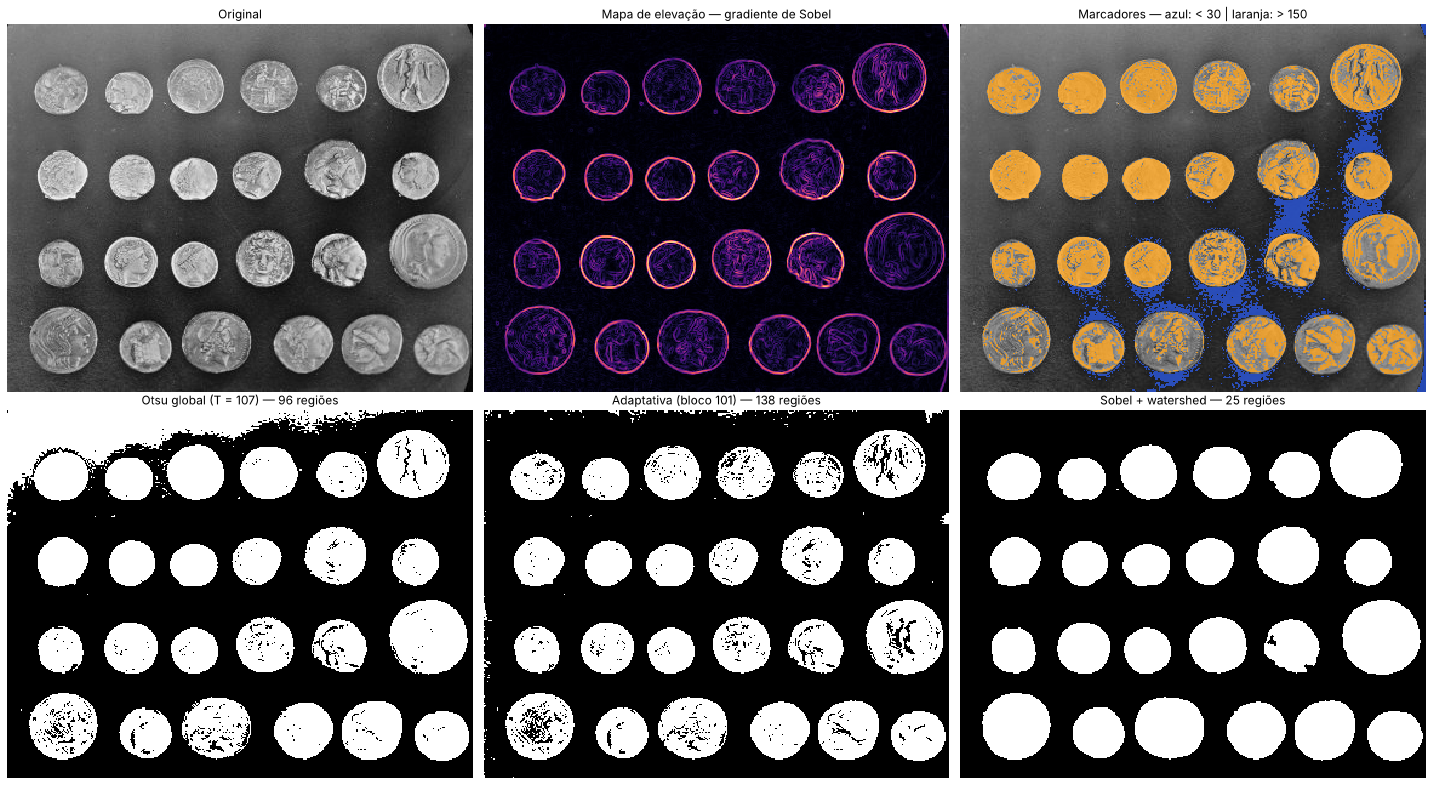

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Original')
axes[0, 1].imshow(elevacao, cmap='magma')
axes[0, 1].set_title('Mapa de elevação — gradiente de Sobel')

cores_marc = np.zeros((*img.shape, 4))
cores_marc[marcadores == 1] = [0.2, 0.4, 1.0, 0.7]   # azul: fundo
cores_marc[marcadores == 2] = [1.0, 0.6, 0.0, 0.7]   # laranja: moeda
axes[0, 2].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 2].imshow(cores_marc)
axes[0, 2].set_title(f'Marcadores — azul: < {LIMIAR_FUNDO} | laranja: > {LIMIAR_MOEDA}')

for col, (nome, m) in enumerate(segmentacoes.items()):
    axes[1, col].imshow(m, cmap='gray')
    axes[1, col].set_title(f'{nome} — {measure.label(m, connectivity=2).max()} regiões')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3.4 Medições de apoio

Três medições para entender **onde** cada método erra e o quanto o watershed depende dos parâmetros:

- **erro do Otsu por fileira:** usando a máscara do watershed como referência, a fração dos pixels de moeda que ficou abaixo do limiar (buracos) em cada fileira, e a fração do fundo que ficou acima (falsos positivos);
- **cobertura dos marcadores por fileira:** que fração de cada moeda recebeu marcador de "moeda certa" — quanto menor, mais o resultado depende da inundação;
- **sensibilidade aos limiares dos marcadores:** o watershed é repetido com outros pares de limiares.

In [ ]:
referencia = ndi.binary_fill_holes(seg_ws)
rotulos_ref = measure.label(referencia, connectivity=2)
fileira_px = np.digitize(np.arange(img.shape[0]), [90, 160, 230])    # fileira de cada linha da imagem
fundo_ref = ~ndi.binary_dilation(referencia, iterations=5)           # fundo com margem de 5 px das bordas

linhas = []
for f in range(4):
    na_fileira = (fileira_px[:, None] == f) & np.ones(img.shape[1], bool)
    moeda_f = referencia & na_fileira
    linhas.append({
        'Fileira': f'{f + 1}' + (' (topo)' if f == 0 else ' (base)' if f == 3 else ''),
        'Brilho médio do fundo': round(float(img[fundo_ref & na_fileira].mean()), 1),
        'Fundo acima do limiar de Otsu (%)': round(100 * np.mean(img[fundo_ref & na_fileira] > limiar_otsu), 1),
        'Moeda abaixo do limiar de Otsu (%)': round(100 * np.mean(img[moeda_f] <= limiar_otsu), 1),
        'Moeda coberta por marcador (%)': round(100 * np.mean(marcadores[moeda_f] == 2), 1),
    })
pd.DataFrame(linhas).set_index('Fileira')

,Brilho médio do fundo,Fundo acima do limiar de Otsu (%),Moeda abaixo do limiar de Otsu (%),Moeda coberta por marcador (%)
Fileira,,,,
1 (topo),95.7,35.8,2.2,70.3
2,61.0,0.1,1.9,82.0
3,49.2,0.0,4.3,62.6
4 (base),48.4,0.0,8.5,37.5


In [ ]:
pares = [(30, 150), (20, 150), (50, 150), (30, 130), (30, 170), (30, 190)]
linhas = []
for baixo, alto in pares:
    m = np.zeros_like(img)
    m[img < baixo] = 1
    m[img > alto] = 2
    seg = segmentation.watershed(elevacao, m) == 2
    linhas.append({'Marcador de fundo': f'< {baixo}', 'Marcador de moeda': f'> {alto}', **resumo_mascara(seg)})
pd.DataFrame(linhas).set_index(['Marcador de fundo', 'Marcador de moeda'])

Regiões  ...  Pixels de objeto (%)
Marcador de fundo Marcador de moeda           ...                      
< 30              > 150                   25  ...                  33.4
< 20              > 150                   25  ...                  33.4
< 50              > 150                   25  ...                  33.4
< 30              > 130                   11  ...                  64.3
                  > 170                   25  ...                  33.4
                  > 190                   25  ...                  33.4

[6 rows x 4 columns]

### 3.5 Interpretação

**1. Por que o método foi escolhido?**

O **watershed sobre o gradiente de Sobel** foi escolhido porque foi o único dos três que produziu uma máscara utilizável: 25 regiões para 24 moedas, contra 96 do Otsu e 138 da limiarização adaptativa.

* **Otsu global (T = 107):** o problema não é o valor do limiar, e sim o fato de ser único. Na fileira do topo, onde o fundo é mais claro (média de 95,7), 35,8% dos pixels de fundo ficaram acima de 107 e foram classificados como moeda: o fundo iluminado se fundiu com as moedas da primeira fileira numa única região de 8.792 px, quase três vezes a maior moeda. Na base, o erro se inverte: 8,5% dos pixels de moeda ficaram abaixo do limiar, abrindo buracos no relevo das moedas mais escuras.
* **Limiarização adaptativa:** resolveu o problema da iluminação — o fundo do topo deixou de ser classificado como moeda —, mas criou outro. Como compara cada pixel com a média local, ela responde a **qualquer** variação local, inclusive ao relevo dentro das moedas: das 138 regiões, 112 têm menos de 50 px. Ela troca o erro de iluminação por um erro de textura.
* **Sobel + watershed:** a decisão sobre os pixels ambíguos é tomada pela **posição das bordas**, e não pelo brilho. Como o contorno das moedas é a transição mais forte da imagem, a inundação para nele, independentemente do brilho local.

**2. Quais dificuldades foram encontradas?**

* **Iluminação não uniforme**, que inviabilizou o limiar único (ver hipótese 1, abaixo).
* **Relevo interno das moedas**, com tons próximos aos do fundo, que fragmentou a limiarização adaptativa.
* **Moedas escuras da base com poucos marcadores:** a cobertura de marcadores cai de 82,0% das moedas da fileira 2 para 37,5% na fileira 4. Nas moedas 19 e 20, apenas ~20% dos pixels passaram de 150; o restante dependeu inteiramente da inundação. O resultado ainda foi correto, mas essas são as moedas mais frágeis do pipeline.
* **Escolha dos limiares dos marcadores:** a tabela de sensibilidade mostra que o resultado é estável numa faixa ampla (fundo entre 20 e 50; moeda entre 150 e 190: sempre 25 regiões). Ele quebra com o marcador de moeda em 130: o fundo iluminado do topo (até ~107, com variações locais acima disso) passa a receber marcadores de moeda, e as regiões caem para 11, com moedas fundidas ao fundo. O limite inferior seguro para esse marcador é, portanto, determinado pelo brilho máximo do fundo.

**3. A segmentação foi satisfatória ou apresentou erros?**

Satisfatória, com um erro residual: **25 regiões para 24 moedas**. A região a mais é um fragmento de 2 px entre as moedas 2 e 6 da primeira fileira (um par de pixels claros isolados cercados por bordas). Esse tipo de erro — pequeno, isolado e menor que qualquer objeto real — é exatamente o que a abertura morfológica remove (Seção 4).

**Revisão das hipóteses da Seção 2:**
* **Hipótese 1 — confirmada, nos dois sentidos previstos:** falsos positivos no topo (35,8% do fundo da fileira 1 acima do limiar; nas demais fileiras, 0,1% ou menos) e buracos que crescem em direção à base (de 2,2% dos pixels de moeda abaixo do limiar na fileira 1 para 8,5% na fileira 4).

## 4. Operações morfológicas

### 4.1 Conceito

A morfologia matemática trata a máscara binária como um **conjunto de pixels** $A$ e a modifica com um pequeno conjunto de referência, o **elemento estruturante** $B$, que percorre a imagem:

| Operação | Definição | Efeito |
|---|---|---|
| Erosão | $A \ominus B$: o pixel fica só se $B$, centrado nele, cabe **inteiro** em $A$ | Encolhe os objetos; apaga estruturas menores que $B$; separa objetos ligados por pontes finas |
| Dilatação | $A \oplus B$: o pixel entra se $B$, centrado nele, **toca** $A$ | Expande os objetos; fecha furos e frestas menores que $B$; pode unir objetos próximos |
| Abertura | $A \circ B = (A \ominus B) \oplus B$ | Remove o que é menor que $B$ e devolve o tamanho ao que sobrou |
| Fechamento | $A \bullet B = (A \oplus B) \ominus B$ | Preenche o que é menor que $B$ e devolve o tamanho ao que sobrou |

A propriedade que torna a abertura e o fechamento úteis antes de **medir** objetos é que eles são **idempotentes** e quase não alteram o tamanho de estruturas maiores que $B$: a segunda operação desfaz o encolhimento ou a expansão da primeira, mas não traz de volta o que foi apagado (ou preenchido).

**Elemento estruturante.** Foi usado um **disco de raio 3** (7×7 px). O formato de disco acompanha a forma circular das moedas e não favorece nenhuma direção. O raio precisa ser maior que os defeitos a remover (o fragmento de 2 px) e muito menor que os objetos (raio mínimo ≈ 18 px), para que nenhuma moeda desapareça na erosão.

**Sequência adotada.** Antes das operações, os furos internos são preenchidos com `binary_fill_holes`, que marca como objeto todo pixel de fundo sem ligação com a borda da imagem. Em seguida: **abertura** (remove fragmentos) → **fechamento** (suaviza contornos). Erosão e dilatação isoladas são aplicadas sobre a mesma entrada apenas para comparação.

**Implementação.** Existem três formas usuais: `cv2.morphologyEx` (OpenCV), `skimage.morphology` e `scipy.ndimage`. Foi usado o SciPy, porque as funções binárias do scikit-image estão obsoletas desde a versão 0.26; o disco é gerado com `skimage.morphology.disk`.

### 4.2 Implementação

Para cada etapa, são registrados o número de regiões e a variação da área total em relação à entrada (a máscara do watershed).

In [ ]:
elemento = morphology.disk(RAIO_ELEMENTO)

preenchida = ndi.binary_fill_holes(seg_ws)
erosao     = ndi.binary_erosion(preenchida, structure=elemento)
dilatacao  = ndi.binary_dilation(preenchida, structure=elemento)
abertura   = ndi.binary_opening(preenchida, structure=elemento)
fechamento = ndi.binary_closing(abertura, structure=elemento)     # abertura → fechamento
mascara_final = fechamento

etapas = {
    'Watershed (entrada)': seg_ws,
    'Furos preenchidos': preenchida,
    'Erosão': erosao,
    'Dilatação': dilatacao,
    'Abertura': abertura,
    'Abertura → fechamento': fechamento,
}

linhas = []
for nome, m in etapas.items():
    linhas.append({
        'Etapa': nome,
        **resumo_mascara(m),
        'Pixels de objeto': int(m.sum()),
        'Variação da área (%)': round(100 * (m.sum() - seg_ws.sum()) / seg_ws.sum(), 2),
    })
tabela_morf = pd.DataFrame(linhas).set_index('Etapa')
tabela_morf

,Regiões,Regiões < 50 px,Maior região (px),Pixels de objeto (%),Pixels de objeto,Variação da área (%)
Etapa,,,,,,
Watershed (entrada),25,1,3141,33.4,38910,0.00
Furos preenchidos,25,1,3141,33.5,38945,0.09
Erosão,24,0,2596,25.6,29773,-23.48
Dilatação,24,0,3734,42.4,49300,26.70
Abertura,24,0,3139,33.4,38861,-0.13
Abertura → fechamento,24,0,3140,33.4,38865,-0.12


In [ ]:
# Pixels alterados por cada operação em relação à sua entrada
pares_morf = [
    ('Preenchimento', seg_ws, preenchida),
    ('Erosão', preenchida, erosao),
    ('Dilatação', preenchida, dilatacao),
    ('Abertura', preenchida, abertura),
    ('Fechamento', abertura, fechamento),
]
pd.DataFrame([{
    'Operação': nome,
    'Pixels adicionados': int(np.sum(~antes & depois)),
    'Pixels removidos': int(np.sum(antes & ~depois)),
} for nome, antes, depois in pares_morf]).set_index('Operação')

,Pixels adicionados,Pixels removidos
Operação,,
Preenchimento,35,0
Erosão,0,9172
Dilatação,10355,0
Abertura,0,84
Fechamento,9,5


### 4.3 Visualização

1. **Máscara após cada operação**, com o número de regiões no título.
2. **Mapa de diferenças** de cada operação em relação à sua entrada — verde: pixels adicionados; vermelho: pixels removidos; cinza: inalterados. A segunda linha amplia a região entre as moedas 2 e 6, onde está o fragmento espúrio do watershed.

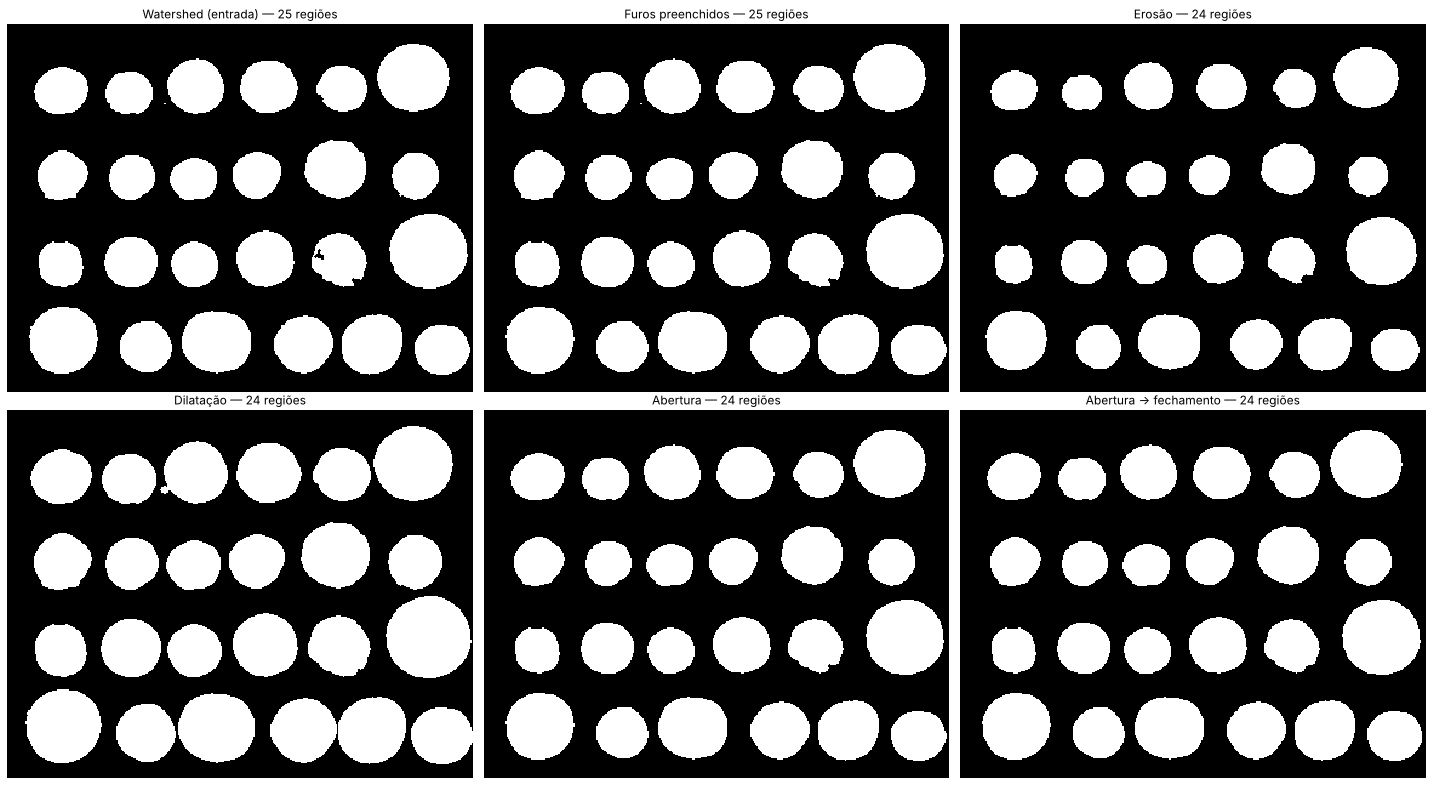

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, (nome, m) in zip(axes.ravel(), etapas.items()):
    ax.imshow(m, cmap='gray')
    ax.set_title(f'{nome} — {measure.label(m, connectivity=2).max()} regiões')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

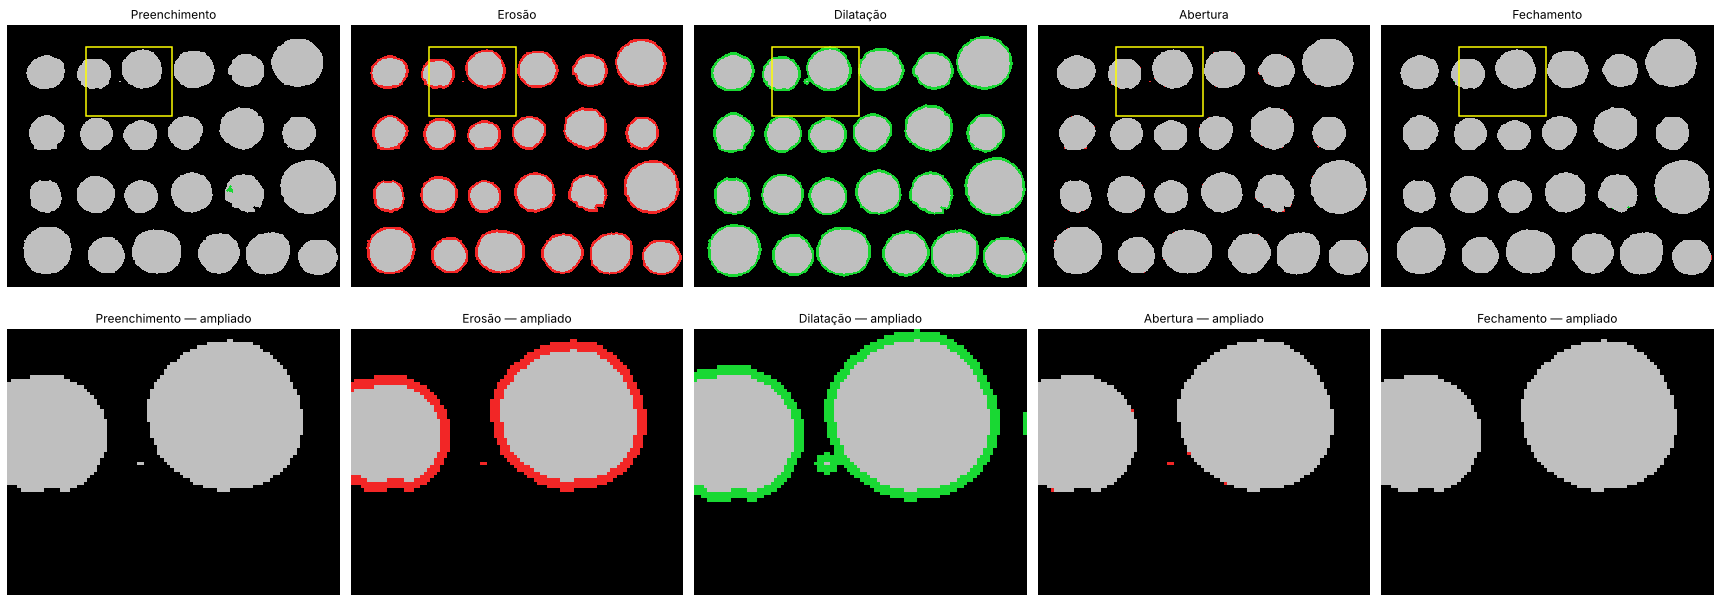

In [ ]:
def mapa_diferenca(antes, depois):
    # Cinza: inalterado | verde: adicionado | vermelho: removido
    vis = np.zeros((*antes.shape, 3))
    vis[antes & depois] = [0.75, 0.75, 0.75]
    vis[~antes & depois] = [0.10, 0.85, 0.20]
    vis[antes & ~depois] = [0.95, 0.15, 0.15]
    return vis

ZOOM = (25, 105, 90, 190)    # (linha_ini, linha_fim, coluna_ini, coluna_fim): entre as moedas 2 e 6
y0, y1, x0, x1 = ZOOM

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
for col, (nome, antes, depois) in enumerate(pares_morf):
    vis = mapa_diferenca(antes, depois)
    axes[0, col].imshow(vis)
    axes[0, col].set_title(nome)
    axes[0, col].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='yellow', lw=1.5))
    axes[1, col].imshow(vis[y0:y1, x0:x1])
    axes[1, col].set_title(f'{nome} — ampliado')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### 4.4 Interpretação

**1. Qual problema cada operação tentou resolver?**

* **Preenchimento de furos:** garantir que cada moeda seja uma região sólida, para que a área e o perímetro meçam o objeto inteiro e não um anel. Adicionou apenas 35 px — bem menos do que o previsto (ver hipótese 2).
* **Erosão (comparação):** eliminar estruturas menores que o disco. Funcionou para o fragmento (25 → 24 regiões), mas removeu uma faixa de ~3 px em volta de todas as moedas: a área total caiu 23,5%. Usada sozinha, distorceria todas as medidas da Seção 6.
* **Dilatação (comparação):** fechar falhas no contorno. Aumentou a área em 26,7% e também removeu o fragmento, mas por outro motivo: ele foi **absorvido** pela moeda vizinha, não apagado. Em imagens com objetos mais próximos, a dilatação uniria moedas vizinhas numa só região.
* **Abertura:** remover o fragmento espúrio **sem** encolher as moedas. O fragmento (2 px) não sobrevive à erosão e, como não existe mais, não é reconstruído pela dilatação. As moedas são reconstruídas: a área total variou apenas −0,13%.
* **Fechamento:** regularizar o contorno após a abertura, preenchendo pequenas reentrâncias. O efeito foi mínimo (9 pixels adicionados e 5 removidos), o que indica que o contorno do watershed já estava regular.

A abertura removeu 84 px no total: 2 do fragmento e o restante em saliências finas do contorno, menores que o disco, que a dilatação não reconstrói.

**2. Quais mudanças ocorreram na estrutura dos objetos?**

* **Erosão e dilatação alteram o tamanho de todos os objetos**: no mapa de diferenças, aparecem como anéis completos ao redor de cada moeda (vermelhos na erosão, verdes na dilatação). A forma é preservada, mas a escala não.
* **Abertura e fechamento alteram apenas detalhes**: o mapa fica quase todo cinza, com pixels isolados nas bordas e o fragmento removido. O número de regiões cai de 25 para 24, e a área total muda menos de 0,2%.
* A dilatação de raio 3 manteve as 24 regiões, o que mostra que o espaço entre moedas vizinhas é maior que 6 px (a expansão somada das duas bordas). Essa margem limita o maior elemento estruturante que pode ser usado sem fundir objetos.

**Revisão das hipóteses da Seção 2:**
* **Hipótese 2 — refutada para o watershed.** O preenchimento alterou apenas 35 px. Os furos previstos de fato aparecem na limiarização (o Otsu deixou 8,5% das moedas da base abaixo do limiar), mas o watershed não os cria: a inundação parte dos marcadores de moeda e se espalha pelo interior antes de alcançar o contorno, então o relevo interno — que tem gradiente mais fraco que a borda — não interrompe a região. O preenchimento continua no pipeline como garantia.

## 5. Identificação de objetos

### 5.1 Conceito

A máscara final diz **quais pixels** são moeda, mas não **a qual moeda** cada pixel pertence. A **rotulagem de componentes conectados** percorre a máscara e atribui o mesmo número inteiro a todos os pixels de objeto que se tocam, e números diferentes a grupos separados. O fundo recebe 0.

O resultado depende da definição de vizinhança: na **vizinhança-4**, dois pixels estão conectados apenas se compartilham um lado; na **vizinhança-8**, também se compartilham um canto. Foi usada a vizinhança-8 (`connectivity=2`), que não parte objetos ligados por pixels diagonais. Como as moedas estão bem separadas, as duas definições dão o mesmo resultado aqui (verificado abaixo).

### 5.2 Implementação e visualização

In [ ]:
rotulos = measure.label(mascara_final, connectivity=2)
regioes = measure.regionprops(rotulos, intensity_image=img)
n_objetos = rotulos.max()

print(f'Objetos encontrados (vizinhança-8): {n_objetos}')
print(f'Objetos encontrados (vizinhança-4): {measure.label(mascara_final, connectivity=1).max()}')

Objetos encontrados (vizinhança-8): 24
Objetos encontrados (vizinhança-4): 24


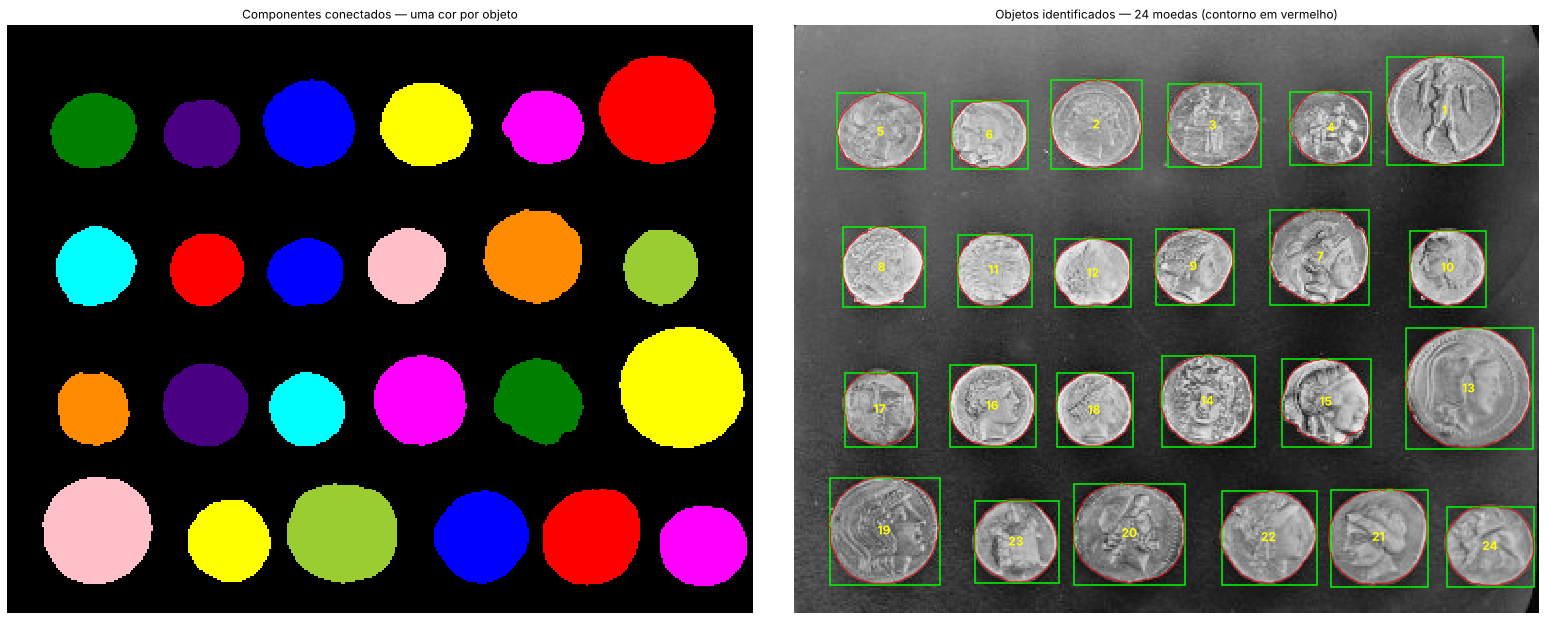

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8.5))
axes[0].imshow(color.label2rgb(rotulos, bg_label=0))
axes[0].set_title('Componentes conectados — uma cor por objeto')

axes[1].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[1].contour(mascara_final, levels=[0.5], colors='red', linewidths=0.8)
for r in regioes:
    lin0, col0, lin1, col1 = r.bbox
    axes[1].add_patch(plt.Rectangle((col0, lin0), col1 - col0, lin1 - lin0,
                                    fill=False, edgecolor='lime', linewidth=1.5))
    axes[1].text(r.centroid[1], r.centroid[0], str(r.label), color='yellow',
                 fontsize=12, fontweight='bold', ha='center', va='center')
axes[1].set_title(f'Objetos identificados — {n_objetos} moedas (contorno em vermelho)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.3 Interpretação

**1. Todos os objetos foram corretamente identificados?**

Sim. Foram encontrados **24 objetos**, o número real de moedas. Cada caixa delimitadora envolve uma única moeda, não há moedas fundidas nem moedas partidas em dois rótulos, e as vizinhanças 4 e 8 dão o mesmo resultado. O contorno vermelho acompanha bem a borda real em quase todas as moedas.

**2. Possíveis causas de erros**

*Observado neste notebook:*
* **Contorno impreciso na moeda 15:** a parte inferior do contorno ficou irregular, entrando no objeto. Nessa região, o relevo interno tem tom próximo ao da borda, e o gradiente do contorno é mais fraco. A contagem não é afetada, mas a área e o perímetro dessa moeda são (ela terá a menor circularidade da tabela da Seção 6).
* **Fragmento espúrio:** sem a abertura, a contagem seria 25 — um falso positivo de 2 px contado como moeda.

*Não ocorreu nesta imagem, mas ocorreria em variações dela:*
* **Objetos encostados:** duas moedas que se tocam formam um único componente conectado (subcontagem). A rotulagem não tem como separá-las; seria preciso um watershed sobre a **transformada de distância** da máscara, cujos máximos ficam nos centros das moedas.
* **Objetos cortados pela borda da imagem:** seriam contados, mas com área e forma incompletas.
* **Parâmetros ajustados para esta imagem:** os limiares dos marcadores (30 e 150) e o raio do disco (3) dependem do brilho do fundo e da distância entre as moedas. Outra foto exigiria novo ajuste.

## 6. Extração de características

### 6.1 Conceito

Cada moeda é descrita por nove características, de três famílias:

| Família | Característica | Definição | O que descreve |
|---|---|---|---|
| Forma | Área | Nº de pixels do objeto | Tamanho |
| Forma | Perímetro | Comprimento do contorno (px) | Tamanho e irregularidade da borda |
| Posição | Centroide | Média das coordenadas (linha, coluna) | Onde o objeto está |
| Forma | Circularidade | $4\pi \cdot \text{área} / \text{perímetro}^2$ | 1 para um círculo perfeito; menor para formas irregulares |
| Forma | Excentricidade | Da elipse com os mesmos momentos de 2ª ordem | 0 para círculo, perto de 1 para formas alongadas |
| Forma | Momento de Hu $\phi_1$ | Combinação dos momentos centrais normalizados | Forma, invariante a translação, rotação e escala |
| Intensidade | Intensidade média | Média dos níveis de cinza do objeto | Brilho (metal, pátina, iluminação) |
| Textura | Contraste GLCM | $\sum_{i,j} (i-j)^2 \, P(i,j)$ | Variação de tom entre vizinhos (relevo marcado → alto) |
| Textura | Homogeneidade GLCM | $\sum_{i,j} P(i,j) / (1 + \lvert i-j \rvert)$ | Uniformidade dos tons (superfície lisa → alta) |

**GLCM.** A matriz de coocorrência de níveis de cinza, $P(i,j)$, conta com que frequência um pixel de tom $i$ tem, a uma distância e direção fixas, um vizinho de tom $j$. Se a superfície é lisa, os pares concentram-se na diagonal ($i \approx j$); se tem relevo, espalham-se.

**Implementação.**
- Forma, posição e intensidade vêm de `skimage.measure.regionprops`. O $\phi_1$ é exibido como $-\text{sinal}(\phi_1)\log_{10}\lvert\phi_1\rvert$, transformação usual porque os momentos de Hu variam várias ordens de grandeza.
- A GLCM (`skimage.feature.graycomatrix`) precisa de uma região retangular. Se fosse calculada sobre a caixa delimitadora, os cantos de fundo escuro entrariam nos pares e a borda moeda/fundo dominaria o contraste. Por isso, foi usado o **quadrado inscrito** na moeda (lado = diâmetro equivalente / √2), centrado no centroide, que contém apenas pixels da moeda.
- As intensidades foram reduzidas de 256 para 32 níveis, para que a matriz (32×32) não fique esparsa com apenas ~500–1.500 pixels por moeda. A matriz é a média de quatro direções (0°, 45°, 90°, 135°) a 1 px de distância, o que reduz a dependência da orientação da moeda.

### 6.2 Implementação

In [ ]:
def textura_glcm(regiao, imagem):
    # Contraste e homogeneidade da GLCM no quadrado inscrito na moeda (sem pixels de fundo).
    lin_c, col_c = map(int, regiao.centroid)
    meio = max(int(regiao.equivalent_diameter_area / 2 / np.sqrt(2)), 2)
    quadrado = imagem[lin_c - meio:lin_c + meio, col_c - meio:col_c + meio] // 8    # 256 → 32 níveis
    glcm = graycomatrix(quadrado.astype(np.uint8), distances=[1],
                        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=32, symmetric=True, normed=True)
    return graycoprops(glcm, 'contrast').mean(), graycoprops(glcm, 'homogeneity').mean()

linhas = []
for r in regioes:
    contraste, homogeneidade = textura_glcm(r, img)
    hu1 = r.moments_hu[0]
    linhas.append({
        'Objeto': r.label,
        'Área (px)': int(r.area),
        'Perímetro (px)': round(r.perimeter, 1),
        'Centroide (lin, col)': f'({r.centroid[0]:.0f}, {r.centroid[1]:.0f})',
        'Circularidade': round(4 * np.pi * r.area / r.perimeter ** 2, 3),
        'Excentricidade': round(r.eccentricity, 3),
        'Hu φ1 (log)': round(-np.sign(hu1) * np.log10(abs(hu1)), 4),
        'Intensidade média': round(r.intensity_mean, 1),
        'Contraste GLCM': round(contraste, 2),
        'Homogeneidade GLCM': round(homogeneidade, 3),
    })

caracteristicas = pd.DataFrame(linhas).set_index('Objeto')
caracteristicas

,Área (px),Perímetro (px),"Centroide (lin, col)",Circularidade,Excentricidade,Hu φ1 (log),Intensidade média,Contraste GLCM,Homogeneidade GLCM
Objeto,,,,,,,,,
1,2602,188.8,"(44, 335)",0.918,0.332,0.7973,156.8,13.55,0.356
2,1651,150.4,"(51, 155)",0.918,0.298,0.7973,169.4,4.89,0.446
3,1616,148.7,"(51, 215)",0.918,0.385,0.7965,157.7,9.53,0.345
4,1221,129.6,"(52, 276)",0.913,0.385,0.7960,154.3,18.67,0.284
5,1354,137.1,"(54, 44)",0.906,0.510,0.7930,167.8,5.12,0.429
6,1099,122.6,"(56, 100)",0.919,0.432,0.7952,184.4,4.57,0.489
7,1914,162.6,"(119, 271)",0.910,0.342,0.7969,158.7,10.77,0.354
8,1290,133.3,"(124, 45)",0.912,0.360,0.7960,190.6,8.10,0.368
9,1206,127.6,"(124, 205)",0.930,0.376,0.7962,172.1,10.02,0.359


### 6.3 Estatísticas descritivas

O **coeficiente de variação** (CV = desvio padrão / média) permite comparar a variabilidade de características com unidades e escalas diferentes: uma característica com CV perto de zero tem praticamente o mesmo valor em todas as moedas e não serve para distingui-las.

In [ ]:
numericas = caracteristicas.drop(columns='Centroide (lin, col)')
estatisticas = numericas.describe().loc[['mean', 'std', 'min', 'max']]
estatisticas.index = ['Média', 'Desvio padrão', 'Mínimo', 'Máximo']
estatisticas.loc['CV (%)'] = 100 * estatisticas.loc['Desvio padrão'] / estatisticas.loc['Média'].abs()
estatisticas.round(3).T.sort_values('CV (%)', ascending=False)

,Média,Desvio padrão,Mínimo,Máximo,CV (%)
Contraste GLCM,9.008,4.436,4.570,20.240,49.252
Área (px),1619.375,546.656,1077.000,3140.000,33.757
Excentricidade,0.341,0.086,0.203,0.510,25.062
Perímetro (px),147.162,23.787,121.200,207.800,16.164
Homogeneidade GLCM,0.397,0.062,0.262,0.489,15.703
Intensidade média,162.796,17.000,131.000,194.700,10.443
Circularidade,0.918,0.017,0.851,0.941,1.902
Hu φ1 (log),0.796,0.001,0.793,0.798,0.169


## 7. Análise dos resultados

### 7.1 Variabilidade e redundância

Duas perguntas orientam a análise: **quanto cada característica varia** entre as moedas (se não varia, não distingue) e **quanto as características se repetem** (duas características com correlação próxima de ±1 carregam a mesma informação).

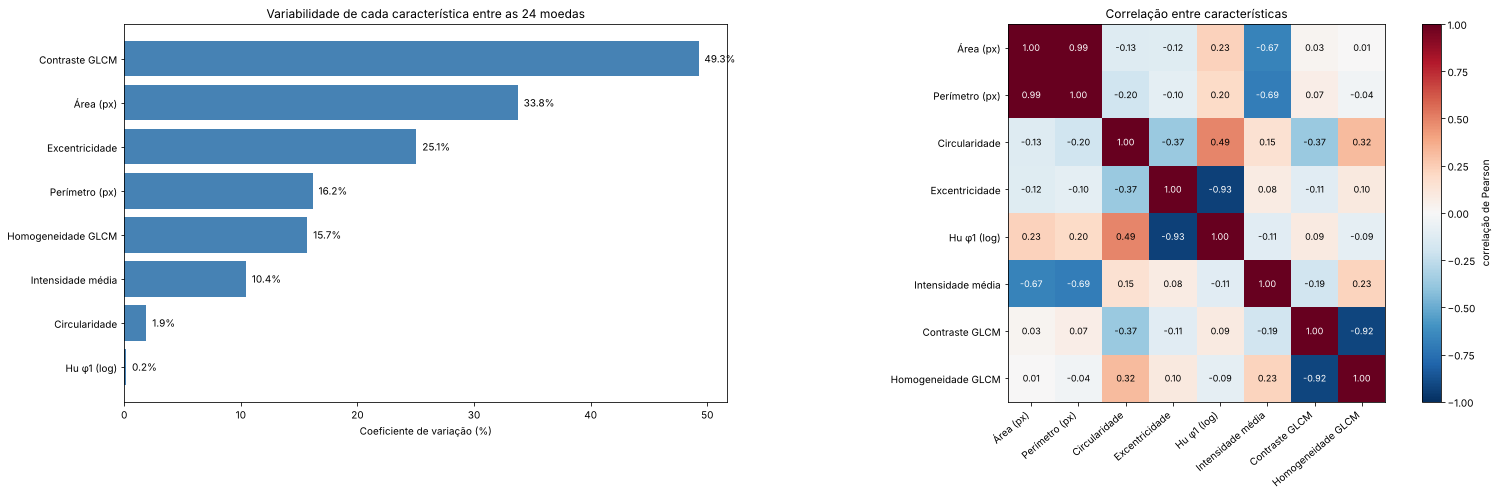

In [ ]:
cv = (100 * numericas.std() / numericas.mean().abs()).sort_values()
correlacao = numericas.corr()

fig, axes = plt.subplots(1, 2, figsize=(21, 7), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].barh(cv.index, cv.values, color='steelblue')
for i, v in enumerate(cv.values):
    axes[0].text(v + 0.5, i, f'{v:.1f}%', va='center')
axes[0].set_xlabel('Coeficiente de variação (%)')
axes[0].set_title('Variabilidade de cada característica entre as 24 moedas')

mapa = axes[1].imshow(correlacao, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(correlacao)))
axes[1].set_xticklabels(correlacao.columns, rotation=40, ha='right')
axes[1].set_yticks(range(len(correlacao)))
axes[1].set_yticklabels(correlacao.columns)
for i in range(len(correlacao)):
    for j in range(len(correlacao)):
        valor = correlacao.iloc[i, j]
        axes[1].text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=9,
                     color='white' if abs(valor) > 0.6 else 'black')
plt.colorbar(mapa, ax=axes[1], fraction=0.04, label='correlação de Pearson')
axes[1].set_title('Correlação entre características')
plt.tight_layout()
plt.show()

### 7.2 Características × posição na imagem

Para testar a hipótese 3, as moedas são coloridas pela **fileira** em que estão. Se a intensidade média refletisse apenas a moeda, as cores ficariam misturadas; se refletir a iluminação, as fileiras formarão faixas.

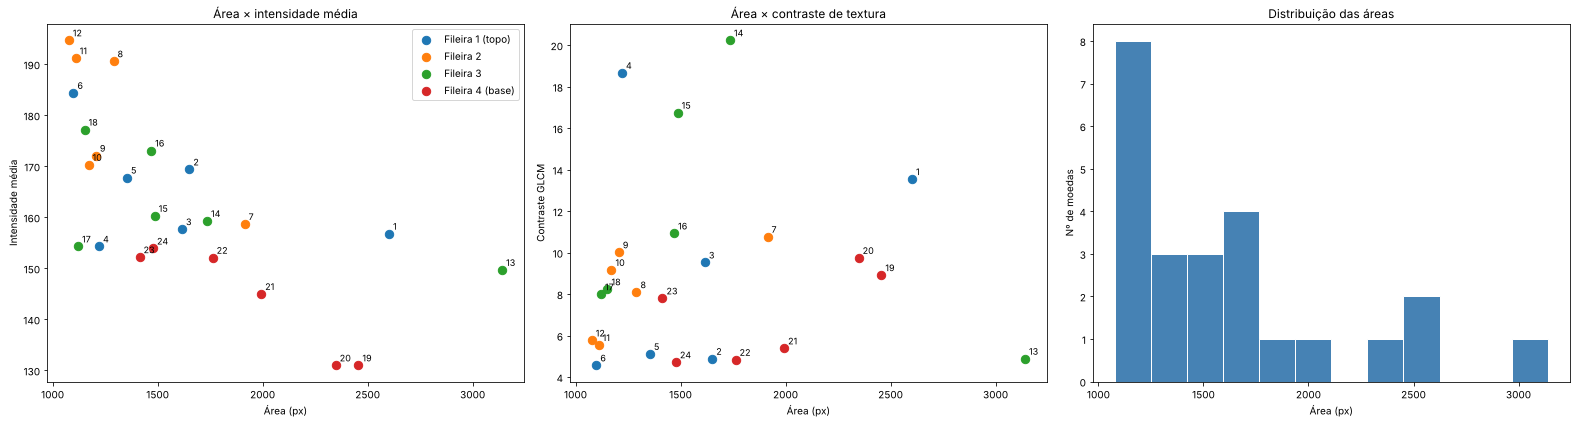

In [ ]:
fileira = np.digitize([r.centroid[0] for r in regioes], [90, 160, 230])
CORES = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
NOMES = ['Fileira 1 (topo)', 'Fileira 2', 'Fileira 3', 'Fileira 4 (base)']

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for f in range(4):
    sel = fileira == f
    axes[0].scatter(numericas['Área (px)'][sel], numericas['Intensidade média'][sel],
                    c=CORES[f], s=70, label=NOMES[f])
    axes[1].scatter(numericas['Área (px)'][sel], numericas['Contraste GLCM'][sel], c=CORES[f], s=70)
for obj, x, y in zip(numericas.index, numericas['Área (px)'], numericas['Intensidade média']):
    axes[0].annotate(str(obj), (x, y), textcoords='offset points', xytext=(4, 4), fontsize=9)
for obj, x, y in zip(numericas.index, numericas['Área (px)'], numericas['Contraste GLCM']):
    axes[1].annotate(str(obj), (x, y), textcoords='offset points', xytext=(4, 4), fontsize=9)

axes[0].set_xlabel('Área (px)')
axes[0].set_ylabel('Intensidade média')
axes[0].set_title('Área × intensidade média')
axes[0].legend()
axes[1].set_xlabel('Área (px)')
axes[1].set_ylabel('Contraste GLCM')
axes[1].set_title('Área × contraste de textura')

axes[2].hist(numericas['Área (px)'], bins=12, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Área (px)')
axes[2].set_ylabel('Nº de moedas')
axes[2].set_title('Distribuição das áreas')
plt.tight_layout()
plt.show()

### 7.3 Teste de uma melhoria: correção de iluminação

A principal limitação identificada até aqui é a iluminação desigual: ela inviabilizou o Otsu (Seção 3) e, possivelmente, contamina a intensidade média. Para verificar, a correção é testada antes de ser recomendada.

A correção usada é a transformada **top-hat**: subtrair da imagem o fundo estimado na Seção 2.3 ($f - (f \circ B)$, com $B$ = disco de raio 35). O resultado mantém as moedas e achata o fundo para perto de zero. Sobre a imagem corrigida, são medidos:

1. o **Otsu global**, antes e depois da mesma morfologia da Seção 4;
2. a **qualidade de cada moeda** segmentada pelo Otsu, comparada à máscara final do watershed;
3. a **intensidade média de cada moeda**, e sua correlação com a área e com a posição vertical.

Contar regiões não basta para avaliar uma segmentação: o número pode estar certo por coincidência, com uma moeda fundida ao fundo compensada por um fragmento extra. Por isso, cada moeda da máscara do watershed é comparada à região do Otsu que mais se sobrepõe a ela, pelo **IoU** (*Intersection over Union*, interseção dividida pela união das duas regiões). O IoU vale 1 para regiões idênticas, e uma moeda é considerada bem segmentada com IoU > 0,9.

In [ ]:
corrigida = (img.astype(np.int16) - fundo_estimado).clip(0, 255).astype(np.uint8)   # top-hat

limiar_corr = filters.threshold_otsu(corrigida)
otsu_corr = corrigida > limiar_corr
otsu_corr_morf = ndi.binary_closing(ndi.binary_opening(ndi.binary_fill_holes(otsu_corr),
                                                       structure=elemento), structure=elemento)

otsu_orig_morf = ndi.binary_closing(ndi.binary_opening(ndi.binary_fill_holes(seg_otsu),
                                                       structure=elemento), structure=elemento)

def iou_por_moeda(mascara):
    # Para cada moeda da referência (watershed), o IoU com a região da máscara que mais se sobrepõe a ela.
    rot = measure.label(mascara, connectivity=2)
    ious = []
    for i in range(1, n_objetos + 1):
        moeda = rotulos == i
        candidatas = [l for l in np.unique(rot[moeda]) if l > 0]
        ious.append(max((np.sum((rot == l) & moeda) / np.sum((rot == l) | moeda) for l in candidatas), default=0))
    return np.array(ious)

intens_corr = [r.intensity_mean for r in measure.regionprops(rotulos, intensity_image=corrigida)]
posicao_lin = [r.centroid[0] for r in regioes]
area = numericas['Área (px)']

comparacao = {}
for nome, limiar, seg, seg_morf, intens in [
        ('Original', limiar_otsu, seg_otsu, otsu_orig_morf, numericas['Intensidade média']),
        ('Corrigida (top-hat)', limiar_corr, otsu_corr, otsu_corr_morf, intens_corr)]:
    areas_morf = np.bincount(measure.label(seg_morf, connectivity=2).ravel())[1:]
    ious = iou_por_moeda(seg_morf)
    comparacao[nome] = {
        'Limiar de Otsu': limiar,
        'Regiões — Otsu': measure.label(seg, connectivity=2).max(),
        'Regiões — Otsu + morfologia': len(areas_morf),
        'Menor região (px)': int(areas_morf.min()),
        'Maior região (px)': int(areas_morf.max()),
        'Moedas com IoU > 0,9': f'{np.sum(ious > 0.9)} de {n_objetos}',
        'Moedas com IoU ≤ 0,9': ', '.join(f'{i + 1} ({v:.2f})' for i, v in enumerate(ious) if v <= 0.9),
        'Correlação intensidade × área': round(np.corrcoef(area, intens)[0, 1], 2),
        'Correlação intensidade × posição vertical': round(np.corrcoef(posicao_lin, intens)[0, 1], 2),
    }
pd.DataFrame(comparacao)

,Original,Corrigida (top-hat)
Limiar de Otsu,107,73
Regiões — Otsu,96,45
Regiões — Otsu + morfologia,25,24
Menor região (px),128,577
Maior região (px),7667,3119
"Moedas com IoU > 0,9",23 de 24,22 de 24
"Moedas com IoU ≤ 0,9",5 (0.18),"4 (0.66), 5 (0.43)"
Correlação intensidade × área,-0.67,-0.29
Correlação intensidade × posição vertical,-0.51,0.38


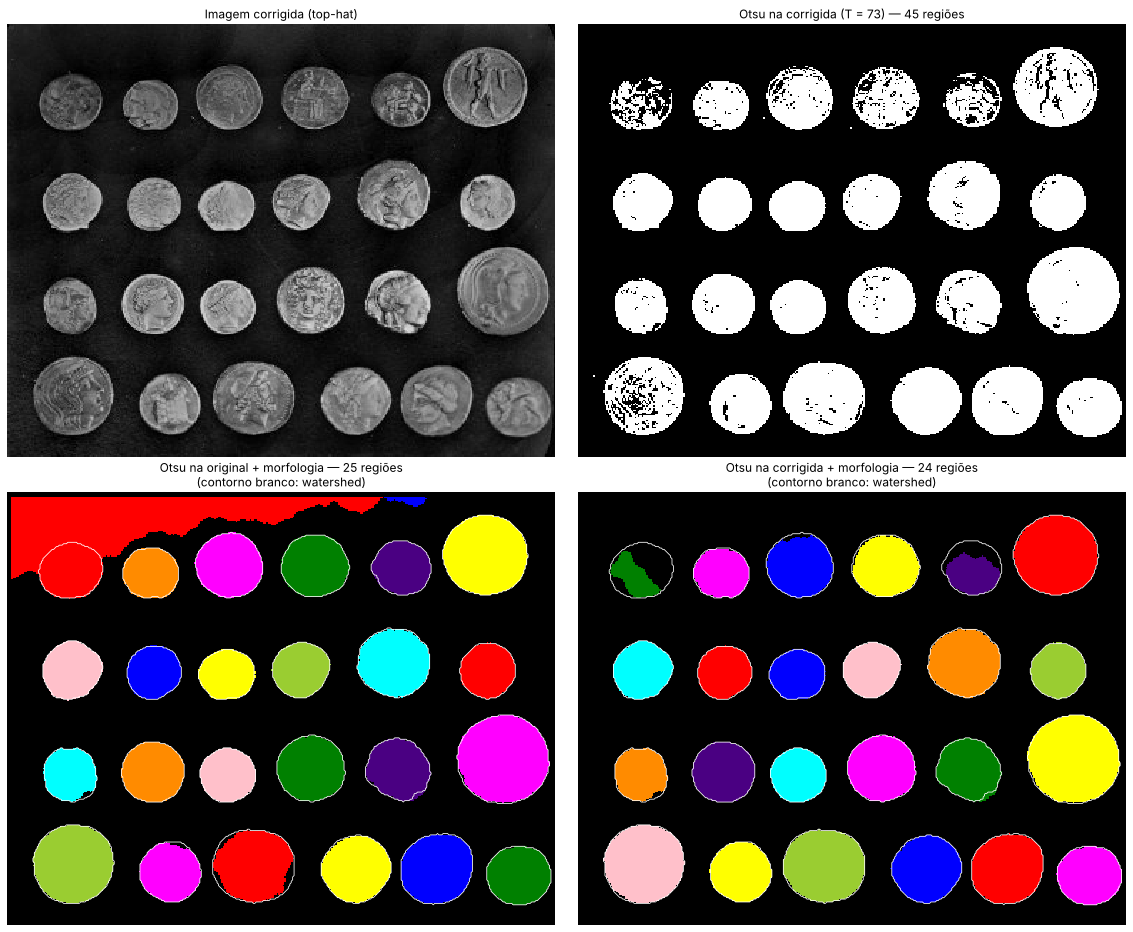

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes[0, 0].imshow(corrigida, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Imagem corrigida (top-hat)')
axes[0, 1].imshow(otsu_corr, cmap='gray')
axes[0, 1].set_title(f'Otsu na corrigida (T = {limiar_corr}) — {measure.label(otsu_corr, connectivity=2).max()} regiões')
paineis = [('Otsu na original + morfologia', otsu_orig_morf), ('Otsu na corrigida + morfologia', otsu_corr_morf)]
for col, (titulo, m) in enumerate(paineis):
    axes[1, col].imshow(color.label2rgb(measure.label(m, connectivity=2), bg_label=0))
    axes[1, col].contour(mascara_final, levels=[0.5], colors='white', linewidths=0.8)
    axes[1, col].set_title(f'{titulo} — {measure.label(m, connectivity=2).max()} regiões\n(contorno branco: watershed)')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### 7.4 Interpretação

**1. As características extraídas conseguem distinguir os objetos?**

Depende da família de características.

* **Tamanho — distingue.** A área vai de 1.077 a 3.140 px (CV ≈ 34%). O histograma mostra um grupo de moedas pequenas (≈ 1.100–1.500 px, a maioria) e moedas maiores espalhadas acima de 1.700 px, com a moeda 13 isolada como a maior. Isso já bastaria para separar as moedas em classes de tamanho.
* **Textura — distingue, e de forma independente do tamanho.** O contraste GLCM é a característica que mais varia (de 4,6 a 20,2; CV ≈ 49%), e sua correlação com a área é praticamente nula (0,03). Moedas com relevo marcado (4, 14 e 15) têm contraste alto; moedas mais lisas ou gastas (13, 22 e 24), contraste baixo. É a única família que descreve o **interior** da moeda, e não o contorno.
* **Forma — não distingue, e isso é esperado.** Circularidade (≈ 0,92 em todas, CV < 2%) e Hu $\phi_1$ (CV ≈ 0,2%) são praticamente constantes, porque todas as moedas são círculos. Elas não separam uma moeda da outra, mas **confirmam que todos os objetos têm forma de moeda** — e seriam decisivas para separar moedas de outros objetos, como parafusos ou chaves. A exceção é a moeda 15 (circularidade 0,85), e a causa é o erro de contorno visto na Seção 5, não a moeda.
* **Excentricidade — varia, mas engana.** O CV de ~25% sugere uma característica informativa, mas todos os valores ficam entre 0,20 e 0,51: formas quase circulares. Para objetos quase redondos, pequenas imprecisões no contorno alteram muito esse número. A variação reflete o **ruído da segmentação**, e não diferenças reais de forma.

**2. Quais características parecem mais informativas?**

| Característica | Varia entre moedas? | Redundante com | Confiável? | Avaliação |
|---|---|---|---|---|
| Área | Sim (CV 34%) | Perímetro (r = 0,99) | Sim | **Mais informativa** — usar uma das duas |
| Contraste GLCM | Sim (CV 49%) | Homogeneidade (r = −0,92) | Sim | **Mais informativa** — independente do tamanho |
| Intensidade média | Pouco (CV 10%) | — | **Não**: depende da iluminação | Usar só após correção |
| Excentricidade | Aparentemente (CV 25%) | Hu $\phi_1$ (r = −0,93) | Não: ruído de contorno | Pouco útil aqui |
| Circularidade, Hu $\phi_1$ | Não (CV < 2%) | — | Sim | Úteis para validar o tipo de objeto |
| Centroide | — | — | Sim | Não descreve a moeda, mas revelou o efeito da iluminação |

**Revisão das hipóteses da Seção 2:**
* **Hipótese 3 — confirmada.** A intensidade média tem correlação de −0,67 com a área, e o gráfico por fileira mostra a causa: as moedas mais escuras (19, 20 e 21, com ~131–145) estão todas na base, a região mais escura da foto, e são justamente moedas grandes; as mais claras (8, 11 e 12, ~191–195) estão na fileira 2, perto do canto iluminado. Após a correção top-hat, a correlação com a área cai para −0,29: a maior parte da relação vinha da iluminação. A correlação com a posição vertical, porém, inverteu de sinal (−0,51 → +0,38), o que indica que a correção **compensou em excesso**: depois dela, as moedas do topo ficaram mais escuras que as da base. A subtração assume que a iluminação apenas **soma** um valor ao brilho de cada região; no canto iluminado, o valor subtraído foi maior do que o efeito real da luz sobre as moedas. É a mesma causa que deixou as moedas 4 e 5 incompletas no teste de segmentação abaixo.

**3. Como o pipeline poderia ser melhorado?**

*Testado neste notebook:*
* **Corrigir a iluminação antes de segmentar — melhora, mas não substitui o watershed.** Com o top-hat, o Otsu global cai de 96 para 45 regiões e, com a mesma morfologia da Seção 4, chega a 24 regiões. A comparação por IoU mostra que esse número esconde dois comportamentos diferentes:
   * **Sem correção**, o Otsu + morfologia dá 25 regiões, um número próximo do correto **por coincidência**. A morfologia limpa a maior parte dos fragmentos e 23 moedas ficam bem segmentadas, mas a moeda 5 continua fundida ao fundo iluminado numa região de 7.667 px (IoU 0,18) — erro grave para qualquer medição —, e um fragmento de 128 px completa a contagem.
   * **Com correção**, a fusão desaparece (maior região: 3.119 px, uma moeda real) e não sobram fragmentos, mas o número de moedas bem segmentadas cai para 22. As moedas 4 e 5, do canto superior esquerdo, ficaram **incompletas** (IoU 0,66 e 0,43): perto do canto iluminado, a correção subtraiu brilho demais e parte delas caiu abaixo do novo limiar.
   * **Saldo:** a correção troca um erro (fusão com o fundo) por outro (moedas incompletas), no mesmo canto da imagem. É o mesmo efeito de compensação excessiva observado na intensidade média (hipótese 3, acima). A correção de iluminação ataca a causa certa, mas exige uma estimativa de fundo melhor que a abertura; nesta imagem, o watershed continua sendo o método mais confiável.

*Propostas:*
* **Estimar o fundo de forma mais precisa** — por exemplo, ajustando uma superfície polinomial suave apenas aos pixels de fundo da máscara do watershed, em vez da abertura — para eliminar a compensação excessiva observada na intensidade e nas moedas 4 e 5.
* **Separar objetos encostados** com watershed sobre a transformada de distância, para que o pipeline funcione em imagens com moedas se tocando.
* **Escolher os marcadores automaticamente**, a partir de percentis do histograma ou de limiarização multinível, em vez dos valores fixos 30 e 150.
* **Converter as medidas para unidades reais** (mm), usando um objeto de referência na foto: a área passaria a identificar o tipo da moeda, e não apenas seu tamanho em pixels.
* **Usar LBP** (*Local Binary Patterns*) como descritor de textura complementar: por comparar cada pixel apenas com seus vizinhos, ele é invariante a mudanças de brilho e não seria afetado pela iluminação.
* **Classificação automática:** com as características normalizadas, um agrupamento (k-means) ou um classificador supervisionado poderia separar as moedas por tipo.

## 8. Conclusão

O pipeline aplicado à imagem `coins` identificou corretamente as **24 moedas** e extraiu nove características de cada uma. O resultado de cada etapa:

| Etapa | Método | Resultado |
|---|---|---|
| Segmentação | Sobel + watershed com marcadores (30 / 150) | 25 regiões (Otsu: 96; adaptativa: 138) |
| Morfologia | Preenchimento → abertura → fechamento, disco de raio 3 | 24 regiões, área total alterada em −0,12% |
| Identificação | Componentes conectados, vizinhança-8 | 24 objetos, sem fusões nem divisões |
| Características | Forma, posição, intensidade e textura (GLCM) | Área e contraste GLCM como as mais informativas |

O fator que mais influenciou o trabalho foi a **iluminação não uniforme**, identificada já na aquisição: o fundo varia de ~25 na base a ~107 no canto superior esquerdo. Ela explicou a falha da limiarização global, as moedas mais frágeis da segmentação (19 e 20, com apenas ~20% de cobertura de marcadores) e a correlação entre intensidade e área. A correção de iluminação por top-hat eliminou a fusão entre moeda e fundo no Otsu, mas compensou em excesso perto do canto iluminado, deixando duas moedas incompletas: troca um erro por outro, e o watershed continua sendo o método mais confiável. O teste também mostrou que **contar regiões não basta para validar uma segmentação**: sem correção, o Otsu com morfologia chegou a 25 regiões com uma moeda fundida ao fundo e um fragmento completando a contagem; só a comparação por IoU revelou o erro.

A comparação entre as operações morfológicas mostrou que a escolha depende da etapa seguinte: erosão e dilatação resolveram o fragmento espúrio, mas alteraram a área total em cerca de 25%; abertura e fechamento resolveram o mesmo problema alterando menos de 0,2%. Quando o objetivo é **medir**, só as operações compostas são adequadas.

Na extração de características, ficou claro que **variar não é o mesmo que informar**. A excentricidade varia, mas por ruído de contorno; a intensidade varia, mas em parte por causa da iluminação; a circularidade não varia e, ainda assim, é útil para confirmar que os objetos são moedas. A área e o contraste GLCM se mostraram as características mais informativas e complementares: uma descreve o tamanho, a outra o relevo interno, com correlação praticamente nula entre si.